In [102]:
import numpy as np
import matplotlib.pyplot as plt 
import pandas as pd
import seaborn as sns
import streamlit as st

In [103]:
uber = pd.read_csv('uber_trips_dataset_50k.csv')

In [104]:
uber.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   trip_id         50000 non-null  int64  
 1   driver_id       50000 non-null  int64  
 2   rider_id        50000 non-null  int64  
 3   city            50000 non-null  str    
 4   pickup_lat      50000 non-null  float64
 5   pickup_lng      50000 non-null  float64
 6   drop_lat        50000 non-null  float64
 7   drop_lng        50000 non-null  float64
 8   distance_km     50000 non-null  float64
 9   fare_amount     50000 non-null  float64
 10  status          50000 non-null  str    
 11  payment_method  50000 non-null  str    
 12  pickup_time     50000 non-null  str    
 13  drop_time       50000 non-null  str    
dtypes: float64(6), int64(3), str(5)
memory usage: 8.7 MB


In [105]:
uber[['pickup_date', 'pickup_time_only']] = uber['pickup_time'].str.split(' ', expand=True)

In [106]:
uber[['drop_date', 'drop_time_only']] = uber['drop_time'].str.split(' ', expand=True)


In [107]:
uber['pickup_time_only'] = pd.to_datetime(uber['pickup_time_only'].astype(str)).dt.strftime('%H:%M:%S')
uber['drop_time_only'] = pd.to_datetime(uber['drop_time_only'].astype(str)).dt.strftime('%H:%M:%S')

C:\Users\harsh\AppData\Local\Temp\ipykernel_15604\408015900.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  uber['pickup_time_only'] = pd.to_datetime(uber['pickup_time_only'].astype(str)).dt.strftime('%H:%M:%S')
C:\Users\harsh\AppData\Local\Temp\ipykernel_15604\408015900.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  uber['drop_time_only'] = pd.to_datetime(uber['drop_time_only'].astype(str)).dt.strftime('%H:%M:%S')


In [108]:
uber.drop(columns=['pickup_time', 'drop_time'], inplace=True)

In [109]:
uber

,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount,status,payment_method,pickup_date,pickup_time_only,drop_date,drop_time_only
0,1,8270,10683,San Francisco,37.170931,-77.586479,37.173652,-77.619934,2.97,10.71,Completed,Wallet,2023-01-01,00:00:00,2023-01-01,00:08:54
1,2,1860,44743,Boston,38.898127,-108.582977,38.937464,-108.558727,8.43,22.41,Completed,UPI,2023-01-01,00:01:00,2023-01-01,00:26:17
2,3,6390,75839,San Francisco,38.814571,-89.942603,38.821702,-89.896435,5.46,12.91,Completed,Cash,2023-01-01,00:02:00,2023-01-01,00:18:22
3,4,6191,22189,New York,37.295906,-75.328844,37.301375,-75.317488,6.61,15.70,Completed,Wallet,2023-01-01,00:03:00,2023-01-01,00:22:49
4,5,6734,61104,Seattle,38.972395,-121.482913,38.992088,-121.467904,10.50,19.15,Completed,Wallet,2023-01-01,00:04:00,2023-01-01,00:35:30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,4836,99552,Boston,39.087594,-92.313909,39.124554,-92.361690,7.39,18.37,No-Show,Card,2023-02-04,17:15:00,2023-02-04,17:37:10
49996,49997,8309,35750,Los Angeles,39.629770,-83.081404,39.580352,-83.050452,4.89,14.39,Completed,Cash,2023-02-04,17:16:00,2023-02-04,17:30:40
49997,49998,8381,36652,San Francisco,37.052628,-89.241586,37.094407,-89.193332,4.19,13.22,Completed,Card,2023-02-04,17:17:00,2023-02-04,17:29:34
49998,49999,5474,43848,Chicago,37.588881,-117.889704,37.612300,-117.886773,2.31,6.72,Cancelled,Card,2023-02-04,17:18:00,2023-02-04,17:24:55


In [110]:
uber['pickup_date'] = pd.to_datetime(uber['pickup_date'])
uber['drop_date'] = pd.to_datetime(uber['drop_date'])

In [111]:
uber

,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount,status,payment_method,pickup_date,pickup_time_only,drop_date,drop_time_only
0,1,8270,10683,San Francisco,37.170931,-77.586479,37.173652,-77.619934,2.97,10.71,Completed,Wallet,2023-01-01,00:00:00,2023-01-01,00:08:54
1,2,1860,44743,Boston,38.898127,-108.582977,38.937464,-108.558727,8.43,22.41,Completed,UPI,2023-01-01,00:01:00,2023-01-01,00:26:17
2,3,6390,75839,San Francisco,38.814571,-89.942603,38.821702,-89.896435,5.46,12.91,Completed,Cash,2023-01-01,00:02:00,2023-01-01,00:18:22
3,4,6191,22189,New York,37.295906,-75.328844,37.301375,-75.317488,6.61,15.70,Completed,Wallet,2023-01-01,00:03:00,2023-01-01,00:22:49
4,5,6734,61104,Seattle,38.972395,-121.482913,38.992088,-121.467904,10.50,19.15,Completed,Wallet,2023-01-01,00:04:00,2023-01-01,00:35:30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,4836,99552,Boston,39.087594,-92.313909,39.124554,-92.361690,7.39,18.37,No-Show,Card,2023-02-04,17:15:00,2023-02-04,17:37:10
49996,49997,8309,35750,Los Angeles,39.629770,-83.081404,39.580352,-83.050452,4.89,14.39,Completed,Cash,2023-02-04,17:16:00,2023-02-04,17:30:40
49997,49998,8381,36652,San Francisco,37.052628,-89.241586,37.094407,-89.193332,4.19,13.22,Completed,Card,2023-02-04,17:17:00,2023-02-04,17:29:34
49998,49999,5474,43848,Chicago,37.588881,-117.889704,37.612300,-117.886773,2.31,6.72,Cancelled,Card,2023-02-04,17:18:00,2023-02-04,17:24:55


In [112]:
uber['pickup_time_only'] = pd.to_datetime(uber['pickup_time_only']).dt.strftime('%H:%M:%S')

uber['drop_time_only'] = pd.to_datetime(uber['drop_time_only']).dt.strftime('%H:%M:%S')

C:\Users\harsh\AppData\Local\Temp\ipykernel_15604\1875217553.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  uber['pickup_time_only'] = pd.to_datetime(uber['pickup_time_only']).dt.strftime('%H:%M:%S')
C:\Users\harsh\AppData\Local\Temp\ipykernel_15604\1875217553.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  uber['drop_time_only'] = pd.to_datetime(uber['drop_time_only']).dt.strftime('%H:%M:%S')


In [113]:
uber

,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount,status,payment_method,pickup_date,pickup_time_only,drop_date,drop_time_only
0,1,8270,10683,San Francisco,37.170931,-77.586479,37.173652,-77.619934,2.97,10.71,Completed,Wallet,2023-01-01,00:00:00,2023-01-01,00:08:54
1,2,1860,44743,Boston,38.898127,-108.582977,38.937464,-108.558727,8.43,22.41,Completed,UPI,2023-01-01,00:01:00,2023-01-01,00:26:17
2,3,6390,75839,San Francisco,38.814571,-89.942603,38.821702,-89.896435,5.46,12.91,Completed,Cash,2023-01-01,00:02:00,2023-01-01,00:18:22
3,4,6191,22189,New York,37.295906,-75.328844,37.301375,-75.317488,6.61,15.70,Completed,Wallet,2023-01-01,00:03:00,2023-01-01,00:22:49
4,5,6734,61104,Seattle,38.972395,-121.482913,38.992088,-121.467904,10.50,19.15,Completed,Wallet,2023-01-01,00:04:00,2023-01-01,00:35:30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,4836,99552,Boston,39.087594,-92.313909,39.124554,-92.361690,7.39,18.37,No-Show,Card,2023-02-04,17:15:00,2023-02-04,17:37:10
49996,49997,8309,35750,Los Angeles,39.629770,-83.081404,39.580352,-83.050452,4.89,14.39,Completed,Cash,2023-02-04,17:16:00,2023-02-04,17:30:40
49997,49998,8381,36652,San Francisco,37.052628,-89.241586,37.094407,-89.193332,4.19,13.22,Completed,Card,2023-02-04,17:17:00,2023-02-04,17:29:34
49998,49999,5474,43848,Chicago,37.588881,-117.889704,37.612300,-117.886773,2.31,6.72,Cancelled,Card,2023-02-04,17:18:00,2023-02-04,17:24:55


In [115]:
pickup = pd.to_datetime(uber['pickup_time_only'], format='%H:%M:%S')
drop = pd.to_datetime(uber['drop_time_only'], format='%H:%M:%S')

In [117]:
uber['duration_minutes'] = (drop - pickup).dt.total_seconds() / 60
uber


,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount,status,payment_method,pickup_date,pickup_time_only,drop_date,drop_time_only,duration_minutes
0,1,8270,10683,San Francisco,37.170931,-77.586479,37.173652,-77.619934,2.97,10.71,Completed,Wallet,2023-01-01,00:00:00,2023-01-01,00:08:54,8.900000
1,2,1860,44743,Boston,38.898127,-108.582977,38.937464,-108.558727,8.43,22.41,Completed,UPI,2023-01-01,00:01:00,2023-01-01,00:26:17,25.283333
2,3,6390,75839,San Francisco,38.814571,-89.942603,38.821702,-89.896435,5.46,12.91,Completed,Cash,2023-01-01,00:02:00,2023-01-01,00:18:22,16.366667
3,4,6191,22189,New York,37.295906,-75.328844,37.301375,-75.317488,6.61,15.70,Completed,Wallet,2023-01-01,00:03:00,2023-01-01,00:22:49,19.816667
4,5,6734,61104,Seattle,38.972395,-121.482913,38.992088,-121.467904,10.50,19.15,Completed,Wallet,2023-01-01,00:04:00,2023-01-01,00:35:30,31.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,4836,99552,Boston,39.087594,-92.313909,39.124554,-92.361690,7.39,18.37,No-Show,Card,2023-02-04,17:15:00,2023-02-04,17:37:10,22.166667
49996,49997,8309,35750,Los Angeles,39.629770,-83.081404,39.580352,-83.050452,4.89,14.39,Completed,Cash,2023-02-04,17:16:00,2023-02-04,17:30:40,14.666667
49997,49998,8381,36652,San Francisco,37.052628,-89.241586,37.094407,-89.193332,4.19,13.22,Completed,Card,2023-02-04,17:17:00,2023-02-04,17:29:34,12.566667
49998,49999,5474,43848,Chicago,37.588881,-117.889704,37.612300,-117.886773,2.31,6.72,Cancelled,Card,2023-02-04,17:18:00,2023-02-04,17:24:55,6.916667


In [118]:
uber['duration_minutes'] = uber['duration_minutes'].round(2)
uber

,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount,status,payment_method,pickup_date,pickup_time_only,drop_date,drop_time_only,duration_minutes
0,1,8270,10683,San Francisco,37.170931,-77.586479,37.173652,-77.619934,2.97,10.71,Completed,Wallet,2023-01-01,00:00:00,2023-01-01,00:08:54,8.90
1,2,1860,44743,Boston,38.898127,-108.582977,38.937464,-108.558727,8.43,22.41,Completed,UPI,2023-01-01,00:01:00,2023-01-01,00:26:17,25.28
2,3,6390,75839,San Francisco,38.814571,-89.942603,38.821702,-89.896435,5.46,12.91,Completed,Cash,2023-01-01,00:02:00,2023-01-01,00:18:22,16.37
3,4,6191,22189,New York,37.295906,-75.328844,37.301375,-75.317488,6.61,15.70,Completed,Wallet,2023-01-01,00:03:00,2023-01-01,00:22:49,19.82
4,5,6734,61104,Seattle,38.972395,-121.482913,38.992088,-121.467904,10.50,19.15,Completed,Wallet,2023-01-01,00:04:00,2023-01-01,00:35:30,31.50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,4836,99552,Boston,39.087594,-92.313909,39.124554,-92.361690,7.39,18.37,No-Show,Card,2023-02-04,17:15:00,2023-02-04,17:37:10,22.17
49996,49997,8309,35750,Los Angeles,39.629770,-83.081404,39.580352,-83.050452,4.89,14.39,Completed,Cash,2023-02-04,17:16:00,2023-02-04,17:30:40,14.67
49997,49998,8381,36652,San Francisco,37.052628,-89.241586,37.094407,-89.193332,4.19,13.22,Completed,Card,2023-02-04,17:17:00,2023-02-04,17:29:34,12.57
49998,49999,5474,43848,Chicago,37.588881,-117.889704,37.612300,-117.886773,2.31,6.72,Cancelled,Card,2023-02-04,17:18:00,2023-02-04,17:24:55,6.92


In [119]:
uber[uber['duration_minutes'] == 0].count()

trip_id             3
driver_id           3
rider_id            3
city                3
pickup_lat          3
pickup_lng          3
drop_lat            3
drop_lng            3
distance_km         3
fare_amount         3
status              3
payment_method      3
pickup_date         3
pickup_time_only    3
drop_date           3
drop_time_only      3
duration_minutes    3
dtype: int64

In [120]:
(uber['duration_minutes'] == 0).sum()

np.int64(3)

In [121]:
uber = uber[~((uber['duration_minutes'] == 0) & (uber['distance_km'] == 0))]

In [122]:
uber['day_of_week'] = pd.to_datetime(uber['pickup_date']).dt.day_name()

In [125]:
uber['pickup_hour'] = pd.to_datetime(uber['pickup_time_only'], format='%H:%M:%S').dt.hour
uber

,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount,status,payment_method,pickup_date,pickup_time_only,drop_date,drop_time_only,duration_minutes,day_of_week,pickup_hour
0,1,8270,10683,San Francisco,37.170931,-77.586479,37.173652,-77.619934,2.97,10.71,Completed,Wallet,2023-01-01,00:00:00,2023-01-01,00:08:54,8.90,Sunday,0
1,2,1860,44743,Boston,38.898127,-108.582977,38.937464,-108.558727,8.43,22.41,Completed,UPI,2023-01-01,00:01:00,2023-01-01,00:26:17,25.28,Sunday,0
2,3,6390,75839,San Francisco,38.814571,-89.942603,38.821702,-89.896435,5.46,12.91,Completed,Cash,2023-01-01,00:02:00,2023-01-01,00:18:22,16.37,Sunday,0
3,4,6191,22189,New York,37.295906,-75.328844,37.301375,-75.317488,6.61,15.70,Completed,Wallet,2023-01-01,00:03:00,2023-01-01,00:22:49,19.82,Sunday,0
4,5,6734,61104,Seattle,38.972395,-121.482913,38.992088,-121.467904,10.50,19.15,Completed,Wallet,2023-01-01,00:04:00,2023-01-01,00:35:30,31.50,Sunday,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,4836,99552,Boston,39.087594,-92.313909,39.124554,-92.361690,7.39,18.37,No-Show,Card,2023-02-04,17:15:00,2023-02-04,17:37:10,22.17,Saturday,17
49996,49997,8309,35750,Los Angeles,39.629770,-83.081404,39.580352,-83.050452,4.89,14.39,Completed,Cash,2023-02-04,17:16:00,2023-02-04,17:30:40,14.67,Saturday,17
49997,49998,8381,36652,San Francisco,37.052628,-89.241586,37.094407,-89.193332,4.19,13.22,Completed,Card,2023-02-04,17:17:00,2023-02-04,17:29:34,12.57,Saturday,17
49998,49999,5474,43848,Chicago,37.588881,-117.889704,37.612300,-117.886773,2.31,6.72,Cancelled,Card,2023-02-04,17:18:00,2023-02-04,17:24:55,6.92,Saturday,17


In [127]:
uber.columns

Index(['trip_id', 'driver_id', 'rider_id', 'city', 'pickup_lat', 'pickup_lng',
       'drop_lat', 'drop_lng', 'distance_km', 'fare_amount', 'status',
       'payment_method', 'pickup_date', 'pickup_time_only', 'drop_date',
       'drop_time_only', 'duration_minutes', 'day_of_week', 'pickup_hour'],
      dtype='str')

In [128]:
uber['city'].value_counts()

city
Boston           8454
San Francisco    8401
Chicago          8344
Los Angeles      8315
New York         8247
Seattle          8236
Name: count, dtype: int64

In [130]:
uber.groupby('city').agg({
    'pickup_lat': ['min', 'max'],
    'pickup_lng': ['min', 'max']
})

pickup_lat             pickup_lng           
                     min        max         min        max
city                                                      
Boston         37.000009  40.999937 -121.988559 -73.004012
Chicago        37.000322  40.999669 -121.998471 -73.003428
Los Angeles    37.000767  40.999511 -121.999465 -73.004693
New York       37.001040  40.999543 -121.995304 -73.025923
San Francisco  37.000506  40.999743 -121.997376 -73.001961
Seattle        37.000063  40.999844 -121.981354 -73.002322

In [134]:
lat1 = np.radians(uber['pickup_lat'])
lon1 = np.radians(uber['pickup_lng'])
lat2 = np.radians(uber['drop_lat'])
lon2 = np.radians(uber['drop_lng'])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2

uber['calculated_distance_km'] = 6371 * 2 * np.arcsin(np.sqrt(a))
uber

,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount,status,payment_method,pickup_date,pickup_time_only,drop_date,drop_time_only,duration_minutes,day_of_week,pickup_hour,calculated_distance_km
0,1,8270,10683,San Francisco,37.170931,-77.586479,37.173652,-77.619934,2.97,10.71,Completed,Wallet,2023-01-01,00:00:00,2023-01-01,00:08:54,8.90,Sunday,0,2.979600
1,2,1860,44743,Boston,38.898127,-108.582977,38.937464,-108.558727,8.43,22.41,Completed,UPI,2023-01-01,00:01:00,2023-01-01,00:26:17,25.28,Sunday,0,4.851174
2,3,6390,75839,San Francisco,38.814571,-89.942603,38.821702,-89.896435,5.46,12.91,Completed,Cash,2023-01-01,00:02:00,2023-01-01,00:18:22,16.37,Sunday,0,4.077696
3,4,6191,22189,New York,37.295906,-75.328844,37.301375,-75.317488,6.61,15.70,Completed,Wallet,2023-01-01,00:03:00,2023-01-01,00:22:49,19.82,Sunday,0,1.174280
4,5,6734,61104,Seattle,38.972395,-121.482913,38.992088,-121.467904,10.50,19.15,Completed,Wallet,2023-01-01,00:04:00,2023-01-01,00:35:30,31.50,Sunday,0,2.545195
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,4836,99552,Boston,39.087594,-92.313909,39.124554,-92.361690,7.39,18.37,No-Show,Card,2023-02-04,17:15:00,2023-02-04,17:37:10,22.17,Saturday,17,5.821265
49996,49997,8309,35750,Los Angeles,39.629770,-83.081404,39.580352,-83.050452,4.89,14.39,Completed,Cash,2023-02-04,17:16:00,2023-02-04,17:30:40,14.67,Saturday,17,6.101300
49997,49998,8381,36652,San Francisco,37.052628,-89.241586,37.094407,-89.193332,4.19,13.22,Completed,Card,2023-02-04,17:17:00,2023-02-04,17:29:34,12.57,Saturday,17,6.317337
49998,49999,5474,43848,Chicago,37.588881,-117.889704,37.612300,-117.886773,2.31,6.72,Cancelled,Card,2023-02-04,17:18:00,2023-02-04,17:24:55,6.92,Saturday,17,2.616822


In [135]:
uber['distance_difference'] = abs(
    uber['distance_km'] - uber['calculated_distance_km']
)

uber['distance_difference'].describe()

count    49997.000000
mean         3.759528
std          2.628048
min          0.000259
25%          1.624712
50%          3.352660
75%          5.440148
max         16.863786
Name: distance_difference, dtype: float64

Because the data is synthetic and also there is an average of 3.75 km difference between distance_km column and calculated_distance_km using Hiversine formula , i decided to drop the original distance column since data differences 

In [137]:
uber.drop(columns = ['distance_km','distance_difference'], inplace=True)

In [138]:
uber

,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,fare_amount,status,payment_method,pickup_date,pickup_time_only,drop_date,drop_time_only,duration_minutes,day_of_week,pickup_hour,calculated_distance_km
0,1,8270,10683,San Francisco,37.170931,-77.586479,37.173652,-77.619934,10.71,Completed,Wallet,2023-01-01,00:00:00,2023-01-01,00:08:54,8.90,Sunday,0,2.979600
1,2,1860,44743,Boston,38.898127,-108.582977,38.937464,-108.558727,22.41,Completed,UPI,2023-01-01,00:01:00,2023-01-01,00:26:17,25.28,Sunday,0,4.851174
2,3,6390,75839,San Francisco,38.814571,-89.942603,38.821702,-89.896435,12.91,Completed,Cash,2023-01-01,00:02:00,2023-01-01,00:18:22,16.37,Sunday,0,4.077696
3,4,6191,22189,New York,37.295906,-75.328844,37.301375,-75.317488,15.70,Completed,Wallet,2023-01-01,00:03:00,2023-01-01,00:22:49,19.82,Sunday,0,1.174280
4,5,6734,61104,Seattle,38.972395,-121.482913,38.992088,-121.467904,19.15,Completed,Wallet,2023-01-01,00:04:00,2023-01-01,00:35:30,31.50,Sunday,0,2.545195
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,4836,99552,Boston,39.087594,-92.313909,39.124554,-92.361690,18.37,No-Show,Card,2023-02-04,17:15:00,2023-02-04,17:37:10,22.17,Saturday,17,5.821265
49996,49997,8309,35750,Los Angeles,39.629770,-83.081404,39.580352,-83.050452,14.39,Completed,Cash,2023-02-04,17:16:00,2023-02-04,17:30:40,14.67,Saturday,17,6.101300
49997,49998,8381,36652,San Francisco,37.052628,-89.241586,37.094407,-89.193332,13.22,Completed,Card,2023-02-04,17:17:00,2023-02-04,17:29:34,12.57,Saturday,17,6.317337
49998,49999,5474,43848,Chicago,37.588881,-117.889704,37.612300,-117.886773,6.72,Cancelled,Card,2023-02-04,17:18:00,2023-02-04,17:24:55,6.92,Saturday,17,2.616822


In [142]:
completed_trips = uber[uber['status'] == 'Completed']
completed_trips


,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,fare_amount,status,payment_method,pickup_date,pickup_time_only,drop_date,drop_time_only,duration_minutes,day_of_week,pickup_hour,calculated_distance_km
0,1,8270,10683,San Francisco,37.170931,-77.586479,37.173652,-77.619934,10.71,Completed,Wallet,2023-01-01,00:00:00,2023-01-01,00:08:54,8.90,Sunday,0,2.979600
1,2,1860,44743,Boston,38.898127,-108.582977,38.937464,-108.558727,22.41,Completed,UPI,2023-01-01,00:01:00,2023-01-01,00:26:17,25.28,Sunday,0,4.851174
2,3,6390,75839,San Francisco,38.814571,-89.942603,38.821702,-89.896435,12.91,Completed,Cash,2023-01-01,00:02:00,2023-01-01,00:18:22,16.37,Sunday,0,4.077696
3,4,6191,22189,New York,37.295906,-75.328844,37.301375,-75.317488,15.70,Completed,Wallet,2023-01-01,00:03:00,2023-01-01,00:22:49,19.82,Sunday,0,1.174280
4,5,6734,61104,Seattle,38.972395,-121.482913,38.992088,-121.467904,19.15,Completed,Wallet,2023-01-01,00:04:00,2023-01-01,00:35:30,31.50,Sunday,0,2.545195
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49992,49993,8143,96851,Boston,40.753889,-77.690919,40.713670,-77.646215,14.70,Completed,UPI,2023-02-04,17:12:00,2023-02-04,17:34:33,22.55,Saturday,17,5.846984
49993,49994,9947,17372,San Francisco,38.849696,-99.415224,38.889193,-99.411172,12.35,Completed,Card,2023-02-04,17:13:00,2023-02-04,17:31:09,18.15,Saturday,17,4.405811
49994,49995,5871,59701,San Francisco,38.545388,-116.403128,38.530489,-116.405080,9.31,Completed,Cash,2023-02-04,17:14:00,2023-02-04,17:26:27,12.45,Saturday,17,1.665393
49996,49997,8309,35750,Los Angeles,39.629770,-83.081404,39.580352,-83.050452,14.39,Completed,Cash,2023-02-04,17:16:00,2023-02-04,17:30:40,14.67,Saturday,17,6.101300


In [143]:
cancelled_no_show = uber[
    uber['status'].isin(['Cancelled', 'No Show'])
]
cancelled_no_show

,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,fare_amount,status,payment_method,pickup_date,pickup_time_only,drop_date,drop_time_only,duration_minutes,day_of_week,pickup_hour,calculated_distance_km
28,29,4005,51388,San Francisco,38.829067,-98.132996,38.830208,-98.096116,20.11,Cancelled,Card,2023-01-01,00:28:00,2023-01-01,00:55:57,27.95,Sunday,0,3.197158
44,45,6486,35605,Boston,40.737827,-85.377073,40.749047,-85.330481,24.29,Cancelled,Cash,2023-01-01,00:44:00,2023-01-01,01:21:12,37.20,Sunday,0,4.118662
49,50,2585,85111,New York,39.386138,-108.382399,39.416854,-108.369592,24.77,Cancelled,UPI,2023-01-01,00:49:00,2023-01-01,01:25:48,36.80,Sunday,0,3.588345
59,60,5297,64012,Los Angeles,40.492556,-74.361363,40.459235,-74.364547,27.04,Cancelled,Wallet,2023-01-01,00:59:00,2023-01-01,01:27:01,28.02,Sunday,0,3.714908
66,67,7863,53424,Boston,37.764366,-82.287327,37.802503,-82.295990,12.04,Cancelled,UPI,2023-01-01,01:06:00,2023-01-01,01:18:30,12.50,Sunday,1,4.308432
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49962,49963,6505,96162,Chicago,38.904645,-84.992567,38.873645,-84.993980,18.01,Cancelled,Cash,2023-02-04,16:42:00,2023-02-04,17:06:55,24.92,Saturday,16,3.449214
49968,49969,5653,31280,San Francisco,38.317880,-83.048542,38.306436,-83.034018,11.66,Cancelled,Card,2023-02-04,16:48:00,2023-02-04,17:04:10,16.17,Saturday,16,1.795874
49984,49985,2124,77936,Seattle,38.658784,-75.329523,38.697856,-75.348095,8.91,Cancelled,Cash,2023-02-04,17:04:00,2023-02-04,17:10:12,6.20,Saturday,17,4.634044
49998,49999,5474,43848,Chicago,37.588881,-117.889704,37.612300,-117.886773,6.72,Cancelled,Card,2023-02-04,17:18:00,2023-02-04,17:24:55,6.92,Saturday,17,2.616822


In [144]:
kpi = {
    'Total Trips': len(uber),
    'Completed Trips': len(completed_trips),
    'Cancelled/No Show Trips': len(cancelled_no_show),
    'Average Duration (minutes)': round(uber['duration_minutes'].mean(), 2),
    'Average Distance (km)': round(uber['calculated_distance_km'].mean(), 2),
    'Sales': round(completed_trips['fare_amount'].sum(), 2),
    'Lost Sales': round(cancelled_no_show['fare_amount'].sum(), 2),}

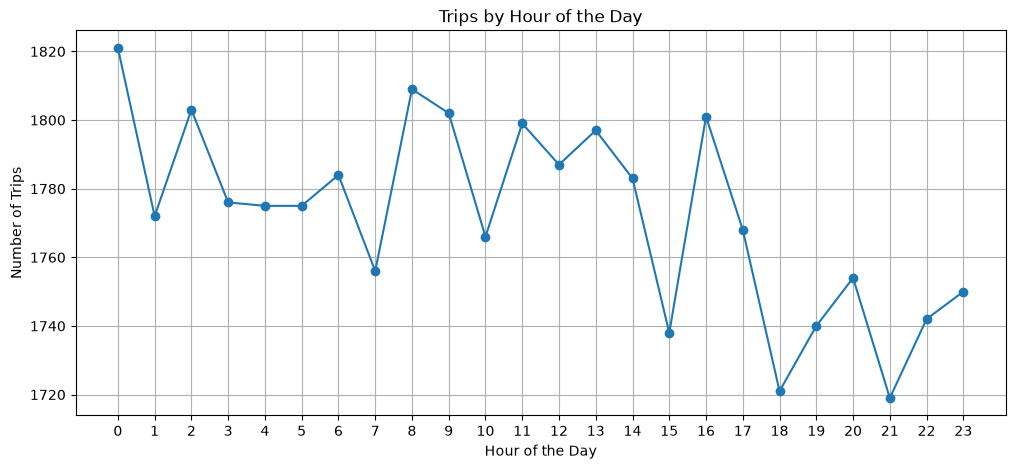

In [149]:
hourly_trips = completed_trips['pickup_hour'].value_counts().sort_index()

hourly_trips.plot(kind='line', marker='o', figsize=(12,5))

plt.title('Trips by Hour of the Day')
plt.xlabel('Hour of the Day')
plt.ylabel('Number of Trips')
plt.xticks(range(24))
plt.grid(True)
plt.show()

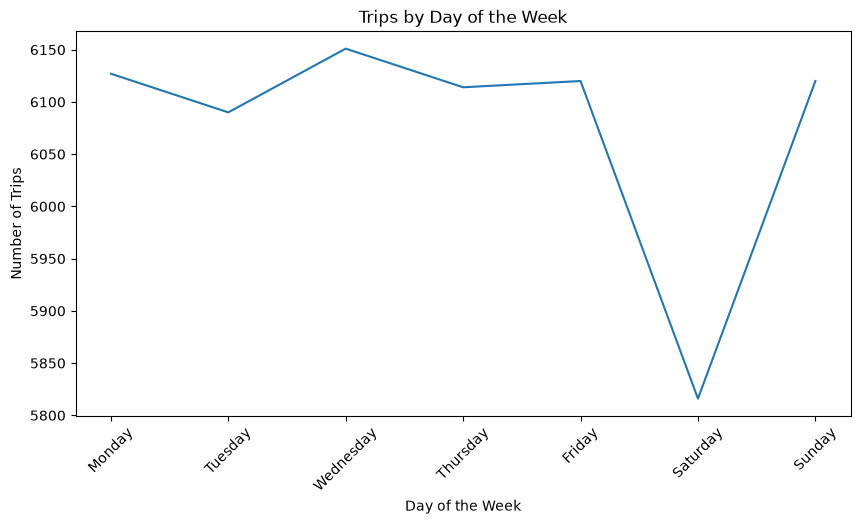

In [151]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
             'Friday', 'Saturday', 'Sunday']

daily_trips = completed_trips['day_of_week'].value_counts().reindex(day_order)

daily_trips.plot(kind='line', figsize=(10,5))

plt.title('Trips by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)
plt.show()

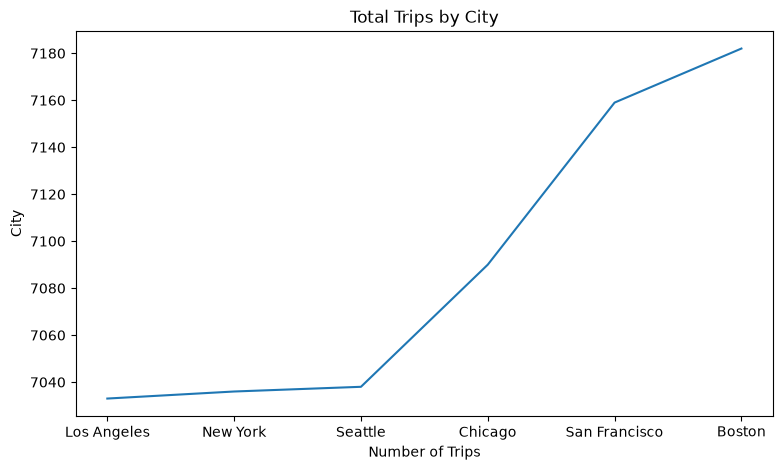

In [157]:
city_trips = completed_trips['city'].value_counts().sort_values(ascending=True)

city_trips.plot(kind='line', figsize=(9,5))

plt.title('Total Trips by City')
plt.xlabel('Number of Trips')
plt.ylabel('City')
plt.show()